In [1]:
import supervision as sv


In [2]:
ds = sv.DetectionDataset.from_coco(images_directory_path="Dataset/image", annotations_path="Dataset/_annotations.coco.json")

ds_train, ds = ds.split(split_ratio=0.7, shuffle=True, random_state=42)
ds_valid, ds_test = ds.split(split_ratio=0.5, shuffle=True, random_state=42)

In [4]:
# ds.as_coco(images_directory_path="rfdetr_dataset/image", annotations_path="rfdetr_dataset/_annotations.coco.json")
ds_train.as_coco(images_directory_path="rfdetr_dataset/train", annotations_path="rfdetr_dataset/train/_annotations.coco.json")

In [5]:
ds_test.as_coco(images_directory_path="rfdetr_dataset/test", annotations_path="rfdetr_dataset/test/_annotations.coco.json")

In [6]:
ds_valid.as_coco(images_directory_path="rfdetr_dataset/valid", annotations_path="rfdetr_dataset/valid/_annotations.coco.json")

In [7]:
from rfdetr import RFDETRNano

model = RFDETRNano()

rf-detr-nano.pth: 100%|██████████| 349M/349M [00:06<00:00, 54.6MiB/s] 


Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Loading pretrain weights


In [8]:
model.train(dataset_dir="rfdetr_dataset", epochs=1, batch_size=2, device="mps", gradient_accumulation_steps=4, lr=1e-4, num_workers=2, save_dir="rfdetr_weights", project="rfdetr_project", name="rfdetr_experiment")

Unable to initialize TensorBoard. Logging is turned off for this session.  Run 'pip install tensorboard' to enable logging.
Not using distributed mode
git:
  sha: eea342e96e9b2ca2d5589d1cfed4fc6347008006, status: clean, branch: main

Namespace(num_classes=12, grad_accum_steps=4, amp=True, lr=0.0001, lr_encoder=0.00015, batch_size=2, weight_decay=0.0001, epochs=1, lr_drop=100, clip_max_norm=0.1, lr_vit_layer_decay=0.8, lr_component_decay=0.7, do_benchmark=False, dropout=0, drop_path=0.0, drop_mode='standard', drop_schedule='constant', cutoff_epoch=0, pretrained_encoder=None, pretrain_weights='rf-detr-nano.pth', pretrain_exclude_keys=None, pretrain_keys_modify_to_load=None, pretrained_distiller=None, encoder='dinov2_windowed_small', vit_encoder_num_layers=12, window_block_indexes=None, position_embedding='sine', out_feature_indexes=[3, 6, 9, 12], freeze_encoder=False, layer_norm=True, rms_norm=False, backbone_lora=False, force_no_pretrain=False, dec_layers=2, dim_feedforward=2048, hidden

Epoch: [0]  [   0/1312]  eta: 10:47:43  lr: 0.000100  class_error: 95.14  loss: 7.7775 (7.7775)  loss_ce: 1.7880 (1.7880)  loss_bbox: 0.2474 (0.2474)  loss_giou: 0.8228 (0.8228)  loss_ce_0: 1.6785 (1.6785)  loss_bbox_0: 0.1533 (0.1533)  loss_giou_0: 0.6538 (0.6538)  loss_ce_enc: 1.7379 (1.7379)  loss_bbox_enc: 0.1072 (0.1072)  loss_giou_enc: 0.5885 (0.5885)  loss_ce_unscaled: 1.7880 (1.7880)  class_error_unscaled: 95.1417 (95.1417)  loss_bbox_unscaled: 0.0495 (0.0495)  loss_giou_unscaled: 0.4114 (0.4114)  cardinality_error_unscaled: 3890.5000 (3890.5000)  loss_ce_0_unscaled: 1.6785 (1.6785)  loss_bbox_0_unscaled: 0.0307 (0.0307)  loss_giou_0_unscaled: 0.3269 (0.3269)  cardinality_error_0_unscaled: 3889.0000 (3889.0000)  loss_ce_enc_unscaled: 1.7379 (1.7379)  loss_bbox_enc_unscaled: 0.0214 (0.0214)  loss_giou_enc_unscaled: 0.2943 (0.2943)  cardinality_error_enc_unscaled: 3890.5000 (3890.5000)  time: 29.6214  data: 7.7735
Epoch: [0]  [  10/1312]  eta: 2:32:58  lr: 0.000100  class_error: 

Test:  [   0/1125]  eta: 2:38:53  class_error: 19.23  loss: 5.0277 (5.0277)  loss_ce: 0.8362 (0.8362)  loss_bbox: 0.1064 (0.1064)  loss_giou: 0.7097 (0.7097)  loss_ce_0: 0.8675 (0.8675)  loss_bbox_0: 0.1087 (0.1087)  loss_giou_0: 0.6996 (0.6996)  loss_ce_enc: 0.8580 (0.8580)  loss_bbox_enc: 0.1090 (0.1090)  loss_giou_enc: 0.7326 (0.7326)  loss_ce_unscaled: 0.8362 (0.8362)  class_error_unscaled: 19.2308 (19.2308)  loss_bbox_unscaled: 0.0213 (0.0213)  loss_giou_unscaled: 0.3548 (0.3548)  cardinality_error_unscaled: 281.5000 (281.5000)  loss_ce_0_unscaled: 0.8675 (0.8675)  loss_bbox_0_unscaled: 0.0217 (0.0217)  loss_giou_0_unscaled: 0.3498 (0.3498)  cardinality_error_0_unscaled: 280.0000 (280.0000)  loss_ce_enc_unscaled: 0.8580 (0.8580)  loss_bbox_enc_unscaled: 0.0218 (0.0218)  loss_giou_enc_unscaled: 0.3663 (0.3663)  cardinality_error_enc_unscaled: 280.0000 (280.0000)  time: 8.4738  data: 7.7161
Test:  [  10/1125]  eta: 0:17:14  class_error: 7.69  loss: 4.0971 (4.2674)  loss_ce: 0.7516 (

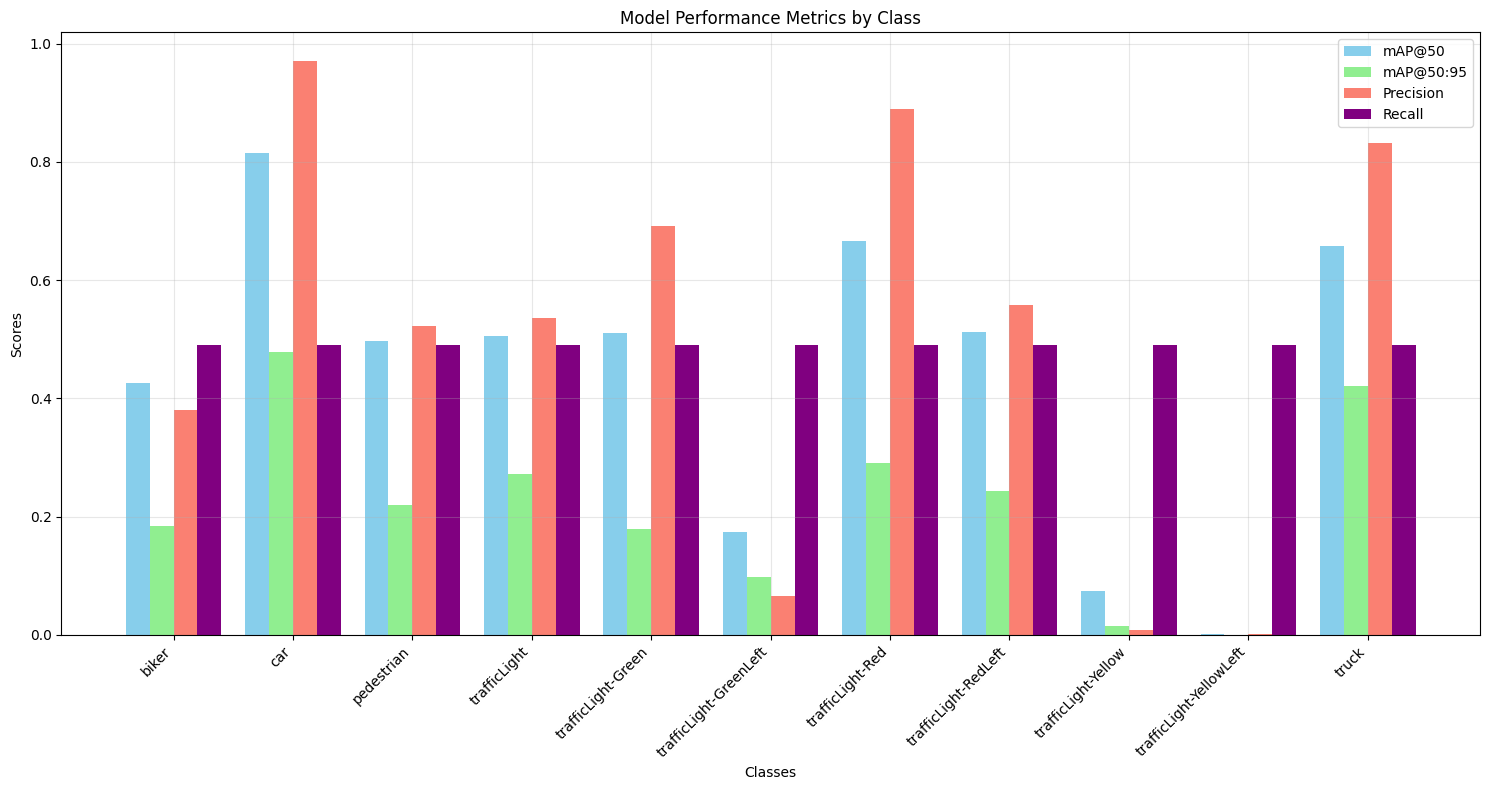

In [10]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the results
with open('output/results.json', 'r') as f:
    results = json.load(f)

# Extract validation results
valid_results = results['class_map']['valid']

# Create a DataFrame
data = []
for item in valid_results:
    if item['class'] != 'all':  # Exclude the 'all' summary row
        data.append({
            'class': item['class'],
            'mAP@50': item['map@50'],
            'mAP@50:95': item['map@50:95'],
            'Precision': item['precision'],
            'Recall': item['recall']
        })

df = pd.DataFrame(data)

# Create the visualization
plt.figure(figsize=(15, 8))
x = range(len(df['class']))

# Plot bars
width = 0.2
plt.bar(x, df['mAP@50'], width, label='mAP@50', color='skyblue')
plt.bar([i + width for i in x], df['mAP@50:95'], width, label='mAP@50:95', color='lightgreen')
plt.bar([i + width * 2 for i in x], df['Precision'], width, label='Precision', color='salmon')
plt.bar([i + width * 3 for i in x], df['Recall'], width, label='Recall', color='purple')

# Customize the plot
plt.xlabel('Classes')
plt.ylabel('Scores')
plt.title('Model Performance Metrics by Class')
plt.xticks([i + width * 1.5 for i in x], df['class'], rotation=45, ha='right')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()